In [ ]:
from google.colab import files

uploaded = files.upload()

Saving social_media_sentiment_10000_synthetic.csv to social_media_sentiment_10000_synthetic.csv


In [ ]:
import os

print(os.listdir())

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv(
    "social_media_sentiment_10000_synthetic.csv"
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

print(df.head())

Dataset loaded successfully!
Dataset Shape: (10000, 2)
                                                text sentiment
0  The shopping experience is really frustrating....  Negative
1  The camera was much worse than expected. I wou...  Negative
2  The restaurant is smooth and convenient. I am ...  Positive
3  The update is extremely disappointing. I would...  Negative
4  The delivery made everything harder. This is n...  Negative


In [ ]:
print("Total Reviews:", len(df))

print("\nSentiment Counts:")

print(df["sentiment"].value_counts())

print("\nMissing Values:")

print(df.isnull().sum())

Total Reviews: 10000

Sentiment Counts:
sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64

Missing Values:
text         0
sentiment    0
dtype: int64


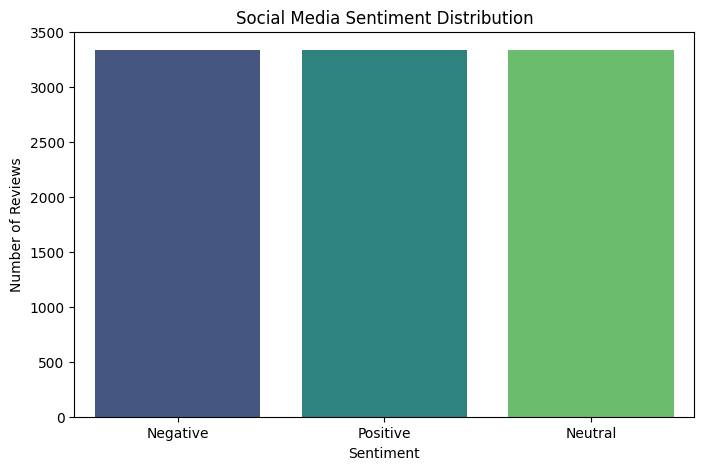

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    palette="viridis",
    legend=False
)

plt.title("Social Media Sentiment Distribution")

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove usernames
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbol
    text = re.sub(r"#", "", text)

    # Remove unwanted special characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
df = df.dropna(subset=["text", "sentiment"]).copy()

df["clean_text"] = df["text"].apply(clean_text)

print(df[["text", "clean_text"]].head(10))

                                                text  \
0  The shopping experience is really frustrating....   
1  The camera was much worse than expected. I wou...   
2  The restaurant is smooth and convenient. I am ...   
3  The update is extremely disappointing. I would...   
4  The delivery made everything harder. This is n...   
5  The support team is extremely disappointing. T...   
6  The customer service is highly recommended. Ke...   
7  The website is difficult to use. I would choos...   
8  The support team wasted my time. Really unhapp...   
9  The customer service is worth every penny. Rea...   

                                          clean_text  
0  the shopping experience is really frustrating ...  
1  the camera was much worse than expected i woul...  
2  the restaurant is smooth and convenient i am g...  
3  the update is extremely disappointing i would ...  
4  the delivery made everything harder this is no...  
5  the support team is extremely disappointing th... 

In [ ]:
sentiment_mapping = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

df["sentiment_label"] = df["sentiment"].map(
    sentiment_mapping
)

print(df[["sentiment", "sentiment_label"]].head())

  sentiment  sentiment_label
0  Negative                0
1  Negative                0
2  Positive                2
3  Negative                0
4  Negative                0


In [ ]:
X = df["clean_text"]

y = df["sentiment_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 8000
Testing Data: 2000


In [ ]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF Feature Extraction Completed!")

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

TF-IDF Feature Extraction Completed!
Training Shape: (8000, 1215)
Testing Shape: (2000, 1215)


In [23]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [24]:
y_pred = model.predict(X_test_tfidf)

print("Predictions Completed!")

print(y_pred[:20])

Predictions Completed!
[0 2 1 2 1 1 2 2 1 2 1 0 0 1 0 1 1 2 0 2]


In [25]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:",
      round(accuracy * 100, 2), "%")

Model Accuracy: 100.0 %


In [26]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=[
        "Negative",
        "Neutral",
        "Positive"
    ]
))

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



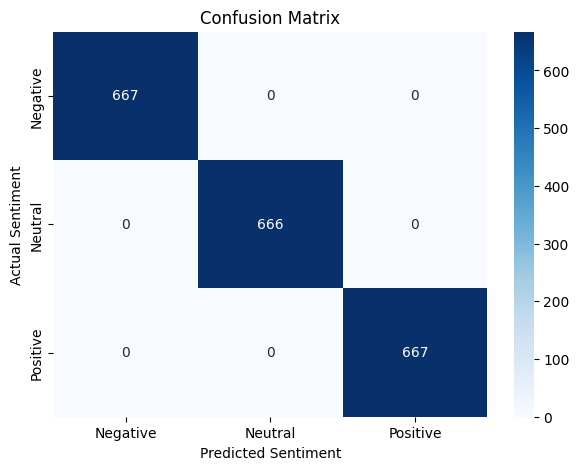

In [27]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("Confusion Matrix")

plt.show()

In [28]:
def predict_sentiment(review):

    cleaned_review = clean_text(review)

    review_vector = vectorizer.transform(
        [cleaned_review]
    )

    prediction = model.predict(
        review_vector
    )[0]

    probabilities = model.predict_proba(
        review_vector
    )[0]

    labels = {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }

    print("Review:", review)

    print("Predicted Sentiment:",
          labels[prediction])

    print("Confidence:",
          round(max(probabilities) * 100, 2), "%")

In [29]:
predict_sentiment(
    "This product is amazing and wonderful!"
)

Review: This product is amazing and wonderful!
Predicted Sentiment: Positive
Confidence: 81.81 %


In [30]:
predict_sentiment(
    "I hate this product. Very disappointing."
)

Review: I hate this product. Very disappointing.
Predicted Sentiment: Negative
Confidence: 68.78 %


In [31]:
predict_sentiment(
    "The product is okay and average."
)

Review: The product is okay and average.
Predicted Sentiment: Neutral
Confidence: 67.33 %


In [32]:
joblib.dump(
    model,
    "sentiment_model.pkl"
)

joblib.dump(
    vectorizer,
    "tfidf_vectorizer.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [34]:
from google.colab import files

files.download("sentiment_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
import joblib
import re

model = joblib.load("sentiment_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def predict_sentiment(text):
    cleaned = clean_text(text)
    vector = vectorizer.transform([cleaned])
    prediction = model.predict(vector)[0]

    labels = {0: "Negative", 1: "Neutral", 2: "Positive"}
    print("Review:", text)
    print("Sentiment:", labels[prediction])

predict_sentiment("I really love this product!")
predict_sentiment("This is a terrible experience.")
predict_sentiment("The product arrived yesterday.")

Review: I really love this product!
Sentiment: Negative
Review: This is a terrible experience.
Sentiment: Negative
Review: The product arrived yesterday.
Sentiment: Positive
